# HW2 — Uniform Convergence and the Limits of Learning
**Statistical and Machine Learning — M2 IM / IMDS / MIAGE, Université de Haute-Alsace**

This notebook studies, through repeated probabilistic simulations, (I) how empirical risks fluctuate around true risks and when they do so *uniformly* over a finite hypothesis class, (II) why no learner can predict the unseen labels of a completely random target (No-Free-Lunch), and (III) how a matching inductive bias (threshold functions) makes generalization possible.

**Notation.** $L_S(h)$ is the empirical risk on a sample $S\sim D^m$, $L_D(h)$ the true risk, and
$$\Delta_S=\max_{h\in\mathcal H}\,|L_S(h)-L_D(h)| .$$
A sample is *$\epsilon$-representative* when $\Delta_S\le\epsilon$, so $\Pr[\Delta_S>\epsilon]$ is the probability that uniform convergence fails at accuracy $\epsilon$. Logarithms are natural. The simulations use only `numpy` and `matplotlib` (`pandas` is used to print result tables); no machine-learning library is involved. A single seeded generator makes every number below reproducible.

**Experimental parameters and why they were chosen**

| Parameter | Values | Justification |
|---|---|---|
| sample size $m$ | from 10 up to 5000, geometric grids | small $m$ exposes the discreteness/skewness of the Binomial, large $m$ exposes concentration; geometric spacing because the quantities of interest decay exponentially in $m$; the grids go beyond the largest theoretical sufficient size (≈ 2000 for $\lvert\mathcal H\rvert=500$, $\epsilon=\delta=0.05$) |
| class size $\lvert\mathcal H\rvert$ | 5, 10, 50, 100, 500 | as suggested; two orders of magnitude, enough to see whether the dependence on $\lvert\mathcal H\rvert$ is linear or logarithmic |
| accuracy $\epsilon$, confidence $\delta$ | $\epsilon\in\{0.05,\,0.1\}$, $\delta=0.05$ | 5–10 % tolerance and 95 % confidence are typical; two values of $\epsilon$ test the $1/\epsilon^2$ scaling |
| true risks $p_j$ | $0.1,\,0.3,\,0.5$ for one hypothesis; for classes either *heterogeneous* ($p_j\sim U[0.05,0.95]$) or *worst case* (all $p_j=\tfrac12$) | $p(1-p)$ is largest at $p=\tfrac12$, the hardest case for concentration; the heterogeneous class is a more typical situation |
| domain size $N$ | 10, 50, 200, 1000 with $m=cN$, $c\in[0.1,4]$ | from a tiny domain to a large one; indexing $m$ by $N$ shows what matters is the ratio $m/N$ |
| repetitions $R$ | 20 000 – 200 000 (one hypothesis), 4 000 (max over up to 500 hypotheses), 2 000 – 5 000 (Parts II–III) | the Monte-Carlo error on a probability is at most $0.5/\sqrt R$ (≤ 0.01 here); more repetitions where very small probabilities must be resolved |

## Setup and theoretical helpers
Besides the imports, this cell defines the theoretical quantities used in Part I: the single-hypothesis Hoeffding bound, the finite-class union bound, the sufficient sample size, and an *exact* Binomial tail probability. The exact tail has no Monte-Carlo noise, so it is used to validate the simulations (and to show what the bounds lose).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from math import log, ceil, lgamma

rng = np.random.default_rng(2026)   # single seeded generator -> the whole notebook is reproducible
TOL = 1e-12                         # guards the strict inequality ">" against floating-point round-off

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.fontsize": 8})
pd.set_option("display.precision", 4)
pd.set_option("display.width", 150)

# ---- theoretical quantities used throughout Part I -------------------------------------------
def hoeffding(m, eps):
    """Hoeffding bound for ONE fixed hypothesis (loss in [0,1]): 2 exp(-2 m eps^2)."""
    return 2 * np.exp(-2 * np.asarray(m, dtype=float) * eps**2)

def union_bound(m, eps, K):
    """Finite-class uniform-convergence bound: 2 |H| exp(-2 m eps^2)."""
    return K * hoeffding(m, eps)

def m_sufficient(eps, delta, K):
    """Sufficient sample size  m >= log(2|H|/delta) / (2 eps^2)."""
    return int(ceil(log(2 * K / delta) / (2 * eps**2)))

# ---- exact Binomial tail (no Monte-Carlo noise): used to validate the simulations -------------
LOGFACT = np.array([lgamma(k + 1) for k in range(20_001)])      # table of log(k!)

def binom_exceed_prob(m, p, eps):
    """Exact Pr[ |E/m - p| > eps ] for E ~ Binomial(m, p)."""
    k = np.arange(m + 1)
    logpmf = LOGFACT[m] - LOGFACT[k] - LOGFACT[m - k] + k * np.log(p) + (m - k) * np.log1p(-p)
    return np.exp(logpmf)[np.abs(k / m - p) > eps + TOL].sum()

---
# Part I — Simulating uniform convergence

**Model.** Each hypothesis $h_j$ has a fixed true risk $L_D(h_j)=p_j$. On a sample of size $m$ it makes $E_j\sim\mathrm{Binomial}(m,p_j)$ mistakes and $L_S(h_j)=E_j/m$. This is exactly the average of $m$ i.i.d. $\{0,1\}$ losses of mean $p_j$, so Hoeffding's inequality applies with range $[0,1]$:
$$\Pr\big[|L_S(h)-L_D(h)|>\epsilon\big]\le 2e^{-2m\epsilon^2}.$$
When the whole class is simulated, the $E_j$ are drawn independently across hypotheses (as in the simplified setup of the statement); the consequences of this choice are discussed at the end of that experiment.

### Task 1 — Empirical risk as a random variable
For three hypotheses with true risks $p\in\{0.1,0.3,0.5\}$ and sample sizes $m\in\{10,50,200,1000\}$, we simulate $E\sim\mathrm{Binomial}(m,p)$ a large number of times, compute $L_S(h)=E/m$, plot its distribution and compare its empirical mean with $p$.

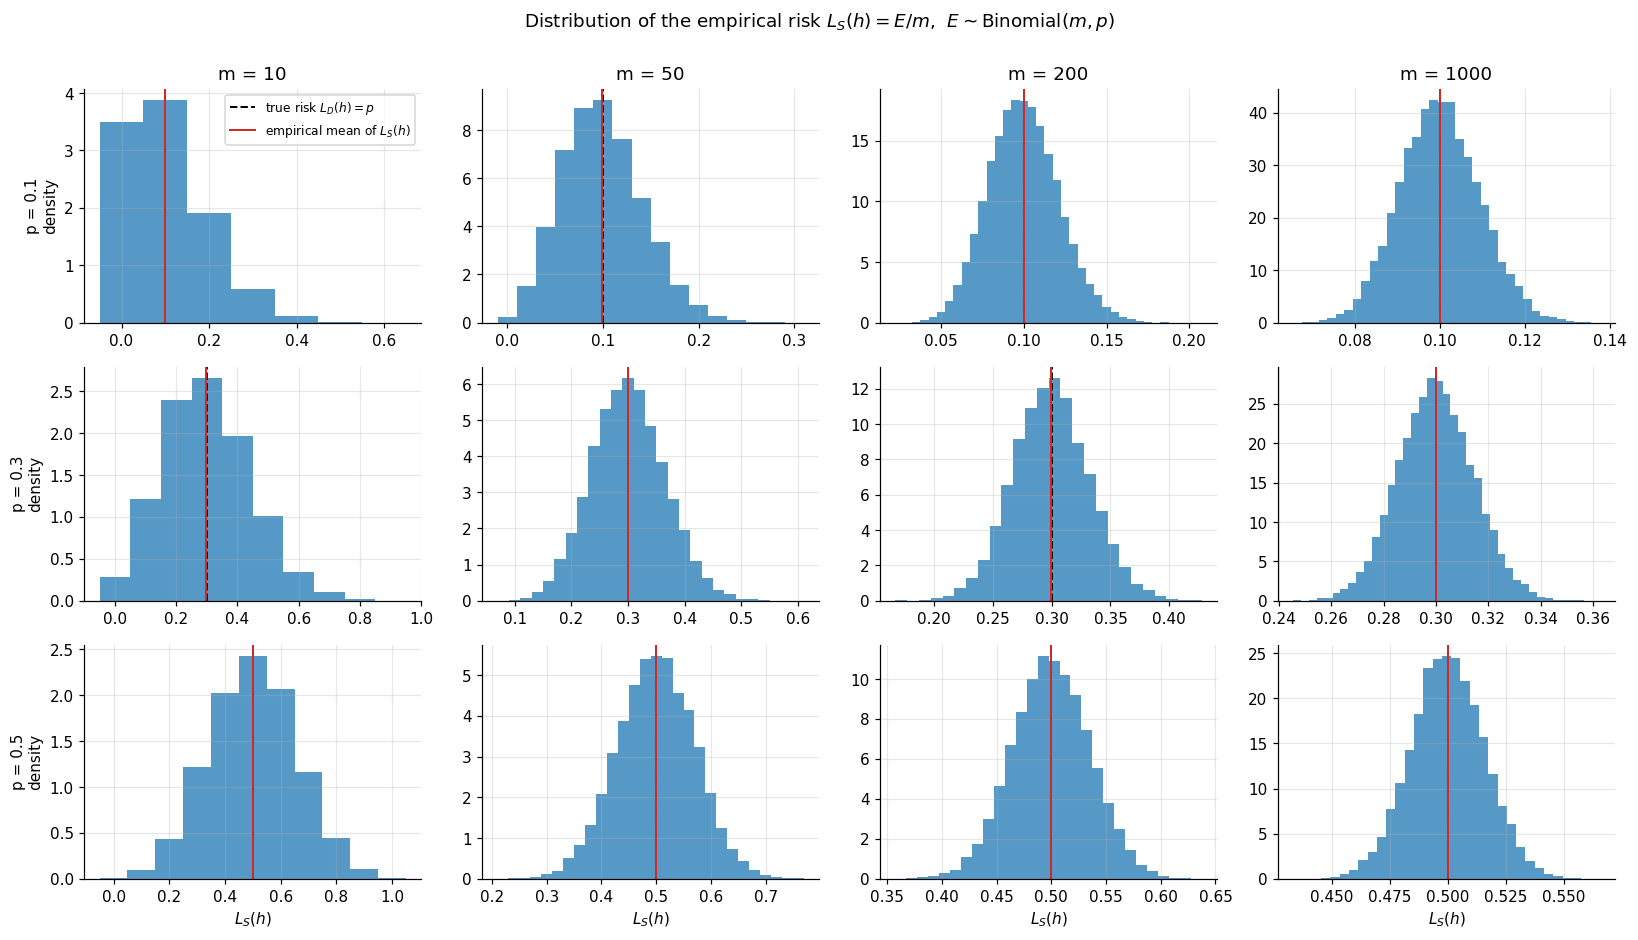

,p,m,mean L_S,mean - p,std error of the mean,std of L_S (sim.),sqrt(p(1-p)/m)
0,0.1,10,0.1001,5.0000e-05,6.7000e-04,0.0953,0.0949
1,0.1,50,0.0993,-6.9000e-04,3.0000e-04,0.0425,0.0424
2,0.1,200,0.0999,-1.0000e-04,1.5000e-04,0.0213,0.0212
3,0.1,1000,0.1000,-4.0000e-05,7.0000e-05,0.0094,0.0095
4,0.3,10,0.2984,-1.5700e-03,1.0300e-03,0.1452,0.1449
5,0.3,50,0.3001,1.4000e-04,4.6000e-04,0.0646,0.0648
6,0.3,200,0.2998,-2.2000e-04,2.3000e-04,0.0323,0.0324
7,0.3,1000,0.2999,-9.0000e-05,1.0000e-04,0.0143,0.0145
8,0.5,10,0.5005,4.6000e-04,1.1200e-03,0.1589,0.1581
9,0.5,50,0.4999,-9.0000e-05,5.0000e-04,0.0710,0.0707


In [2]:
p_values = [0.1, 0.3, 0.5]          # true risks L_D(h) of three representative hypotheses
m_values = [10, 50, 200, 1000]      # from very small to large samples
R1 = 20_000                         # Monte-Carlo repetitions per (p, m)

# For every (p, m): R1 independent training samples, summarised by E ~ Binomial(m, p) and L_S = E / m
samples1 = {(p, m): rng.binomial(m, p, size=R1) / m for p in p_values for m in m_values}

def draw_hist(ax, ls, m, p):
    """Histogram of L_S. L_S only takes the values 0, 1/m, 2/m, ...; each bin groups k consecutive attainable
    values (k = 1 when there are few of them), which avoids the aliasing artefacts of arbitrary bin edges."""
    E = np.rint(ls * m).astype(int)
    lo, hi = E.min(), E.max()
    span = hi - lo + 1
    k = max(1, int(np.ceil(span / 40)))
    edges = (lo - 0.5 + k * np.arange(int(np.ceil(span / k)) + 1)) / m
    ax.hist(ls, bins=edges, density=True, color="tab:blue", alpha=0.75)
    ax.axvline(p, color="k", ls="--", lw=1.3, label=r"true risk $L_D(h)=p$")
    ax.axvline(ls.mean(), color="tab:red", lw=1.3, label=r"empirical mean of $L_S(h)$")

fig, axes = plt.subplots(len(p_values), len(m_values), figsize=(15, 8.5))
for i, p in enumerate(p_values):
    for j, m in enumerate(m_values):
        draw_hist(axes[i, j], samples1[(p, m)], m, p)
        if i == 0: axes[i, j].set_title(f"m = {m}")
        if j == 0: axes[i, j].set_ylabel(f"p = {p}\ndensity")
        if i == len(p_values) - 1: axes[i, j].set_xlabel(r"$L_S(h)$")
axes[0, 0].legend()
fig.suptitle(r"Distribution of the empirical risk $L_S(h)=E/m$,  $E\sim\mathrm{Binomial}(m,p)$", y=1.0)
plt.tight_layout(); plt.show()

rows = []
for (p, m), ls in samples1.items():
    rows.append({"p": p, "m": m, "mean L_S": ls.mean(), "mean - p": ls.mean() - p,
                 "std error of the mean": ls.std(ddof=1) / np.sqrt(R1),
                 "std of L_S (sim.)": ls.std(ddof=1), "sqrt(p(1-p)/m)": np.sqrt(p * (1 - p) / m)})
display(pd.DataFrame(rows).round(5))

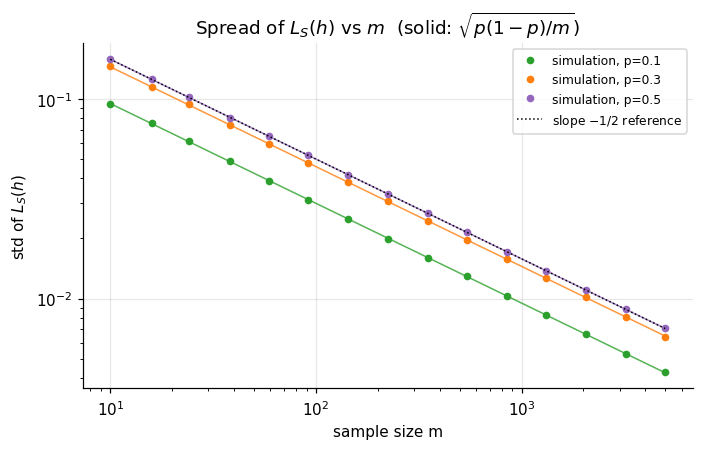

In [3]:
# How fast does the spread of L_S(h) shrink?  Compare the simulated std with sqrt(p(1-p)/m).
m_fine = np.unique(np.round(np.geomspace(10, 5000, 15)).astype(int))

plt.figure(figsize=(6.5, 4.2))
for p, c in zip(p_values, ["tab:green", "tab:orange", "tab:purple"]):
    sd_sim = [rng.binomial(m, p, size=R1).std(ddof=1) / m for m in m_fine]
    plt.loglog(m_fine, sd_sim, "o", color=c, ms=4, label=f"simulation, p={p}")
    plt.loglog(m_fine, np.sqrt(p * (1 - p) / m_fine), "-", color=c, lw=1, alpha=0.8)
plt.loglog(m_fine, 0.5 * m_fine ** -0.5, "k:", lw=1, label=r"slope $-1/2$ reference")
plt.xlabel("sample size m"); plt.ylabel(r"std of $L_S(h)$")
plt.title(r"Spread of $L_S(h)$ vs $m$  (solid: $\sqrt{p(1-p)/m}$)"); plt.legend(); plt.tight_layout(); plt.show()

**Interpretation.**
* **Mean.** The empirical mean of $L_S(h)$ equals $p$ up to Monte-Carlo error (the column *mean − p* is of the order of the standard error of the mean; the largest value is about 2.3 standard errors among 12 comparisons, which is unremarkable). This is unbiasedness: $\mathbb E[E/m]=p=L_D(h)$.
* **Shape.** For $m=10$ the distribution lives on only 11 values and is visibly skewed when $p=0.1$; as $m$ grows it becomes symmetric and bell-shaped (central limit theorem).
* **Variability.** The simulated standard deviation matches $\sqrt{p(1-p)/m}$ (table and log–log plot, slope $-1/2$): multiplying $m$ by 100 (from 10 to 1000) divides the spread by 10. The spread is largest at $p=\tfrac12$, where $p(1-p)$ is maximal.

So $L_S(h)$ concentrates around $L_D(h)$ at rate $1/\sqrt m$; Hoeffding's inequality quantifies this concentration for the *tails*, which is the subject of the next experiment.

### Task 2 — Deviation between empirical and true risk
For every simulated sample we compute $|L_S(h)-L_D(h)|$, estimate $\Pr[|L_S(h)-L_D(h)|>\epsilon]$ for $\epsilon\in\{0.05,0.1\}$ and a grid of sample sizes, and compare it with the Hoeffding bound $2e^{-2m\epsilon^2}$. Two hypotheses are used: $p=0.1$ and the worst case $p=0.5$. The exact Binomial probability is drawn as a noise-free reference. (The strict inequality is evaluated with a tiny tolerance so that floating-point round-off cannot flip the event $|L_S-p|=\epsilon$.)

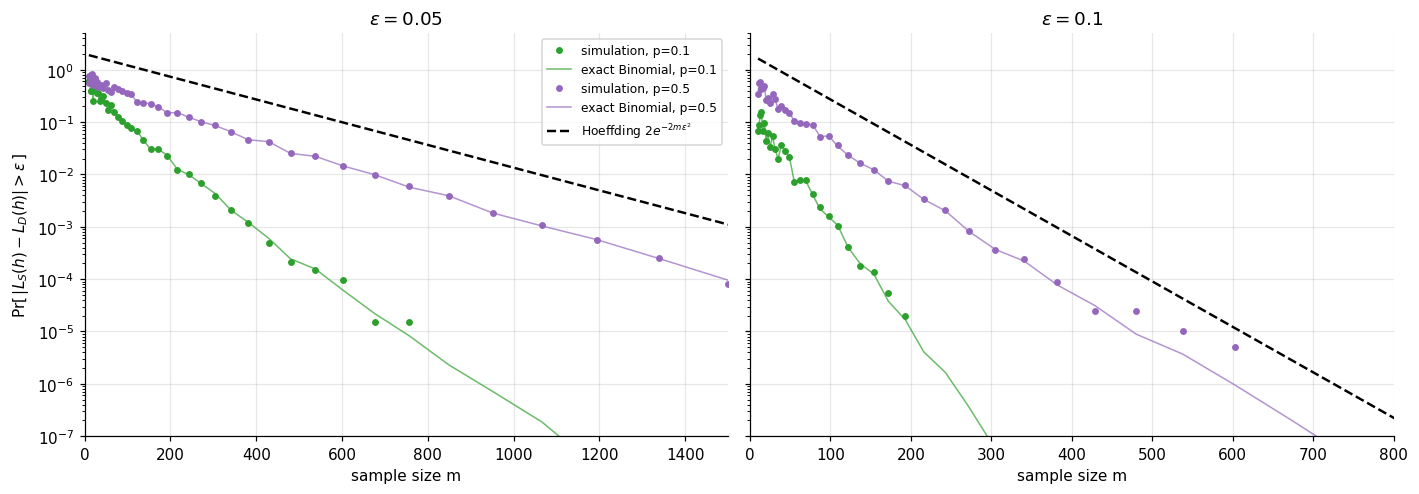

epsilon = 0.05


,p,m,simulated,exact,Hoeffding,Hoeffding / exact
0,0.1,49,2.3136e-01,2.3190e-01,1.5654,6.7503e+00
1,0.1,98,8.9320e-02,9.0204e-02,1.2253,1.3583e+01
2,0.1,193,2.2835e-02,2.3014e-02,0.7620,3.3108e+01
3,0.1,382,1.1600e-03,1.2073e-03,0.2962,2.4530e+02
4,0.1,757,1.5000e-05,8.2476e-06,0.0454,5.5068e+03
5,0.1,1500,0.0000e+00,5.0776e-10,0.0011,2.1785e+06
6,0.5,49,5.6856e-01,5.6817e-01,1.5654,2.7552e+00
7,0.5,98,3.6347e-01,3.6335e-01,1.2253,3.3721e+00
8,0.5,193,1.4974e-01,1.4978e-01,0.7620,5.0871e+00
9,0.5,382,4.5745e-02,4.5856e-02,0.2962,6.4585e+00


In [4]:
eps_list = [0.05, 0.1]                                   # two accuracy levels
p_task2 = [0.1, 0.5]                                     # a "low-variance" and the worst-case (p = 1/2) hypothesis
m_grid2 = np.unique(np.round(np.geomspace(10, 1500, 45)).astype(int))
R2 = 200_000                                             # many repetitions: probabilities down to ~1e-5 are resolved

mc2, ex2 = {}, {}
for p in p_task2:
    tmp = {eps: [] for eps in eps_list}
    for m in m_grid2:
        dev = np.abs(rng.binomial(m, p, size=R2) / m - p)          # |L_S(h) - L_D(h)| for R2 samples
        for eps in eps_list:
            tmp[eps].append(np.mean(dev > eps + TOL))              # estimate of Pr[|L_S - L_D| > eps]
    for eps in eps_list:
        mc2[(p, eps)] = np.array(tmp[eps])
        ex2[(p, eps)] = np.array([binom_exceed_prob(m, p, eps) for m in m_grid2])   # exact Binomial value

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, eps in zip(axes, eps_list):
    for p, c in zip(p_task2, ["tab:green", "tab:purple"]):
        mc = np.where(mc2[(p, eps)] > 0, mc2[(p, eps)], np.nan)     # zeros cannot be drawn on a log axis
        ax.semilogy(m_grid2, mc, "o", color=c, ms=3.5, label=f"simulation, p={p}")
        ax.semilogy(m_grid2, ex2[(p, eps)], "-", color=c, lw=1, alpha=0.7, label=f"exact Binomial, p={p}")
    ax.semilogy(m_grid2, hoeffding(m_grid2, eps), "k--", lw=1.6, label=r"Hoeffding $2e^{-2m\epsilon^2}$")
    ax.set_ylim(1e-7, 5); ax.set_xlim(0, 1500 if eps == 0.05 else 800)
    ax.set_xlabel("sample size m"); ax.set_title(rf"$\epsilon={eps}$")
axes[0].set_ylabel(r"$\Pr[\,|L_S(h)-L_D(h)|>\epsilon\,]$"); axes[0].legend()
plt.tight_layout(); plt.show()

rows = []
for p in p_task2:
    for m0 in [50, 100, 200, 400, 800, 1500]:
        i = int(np.argmin(np.abs(m_grid2 - m0)))
        eps = 0.05
        rows.append({"p": p, "m": m_grid2[i], "simulated": mc2[(p, eps)][i], "exact": ex2[(p, eps)][i],
                     "Hoeffding": hoeffding(m_grid2[i], eps),
                     "Hoeffding / exact": hoeffding(m_grid2[i], eps) / ex2[(p, eps)][i]})
print("epsilon = 0.05")
display(pd.DataFrame(rows))

**Interpretation.**
* The simulated probabilities coincide with the exact Binomial values (up to Monte-Carlo noise, which makes the simulated points disappear at the bottom of the plot once the true probability is below about $10^{-5}$). The curves are slightly jagged because $E/m$ takes discrete values: the event changes only when $m\epsilon$ crosses an integer.
* Hoeffding's bound lies above both curves for every $m$: it is **valid**, but **conservative**, never exact.
  * For small $m$ it is vacuous (larger than 1) — for $m<\ln 2/(2\epsilon^2)\approx 139$ when $\epsilon=0.05$.
  * For the worst case $p=\tfrac12$ it has the right *exponential rate*: the ratio bound/exact grows only slowly, from about 3 (at $m\approx 50$) to about 12 (at $m=1500$). What is lost is a polynomial prefactor of order $\epsilon\sqrt m$ (a Gaussian tail is $\approx e^{-2m\epsilon^2}/(\epsilon\sqrt{2\pi m})$).
  * For $p=0.1$ it is far more conservative (ratio from about 7 to more than $10^6$): Hoeffding only uses the range $[0,1]$ of the loss and ignores the variance $p(1-p)$, so its exponent is too small for low-variance hypotheses (the true exponent is about $m\epsilon^2/(2p(1-p))$).

Hence the bound is a *distribution-free guarantee*: it must hold for every $p$, which is why it is loose for most of them.

### Task 3 — From one hypothesis to uniform convergence
Now $\Delta_S=\max_{h\in\mathcal H}|L_S(h)-L_D(h)|$ is computed for each simulated sample, using all hypotheses at once, and $\Pr[\Delta_S>\epsilon]$ is compared with the finite-class bound $2|\mathcal H|e^{-2m\epsilon^2}$.

**Design.**
* The classes are *nested*, $\mathcal H_5\subset\mathcal H_{10}\subset\dots\subset\mathcal H_{500}$, and the very same simulated samples are used for all of them (the running maximum over $j$). This makes the comparison between class sizes in the next experiment free of sampling noise.
* Two choices of true risks: *heterogeneous* ($p_j\sim U[0.05,0.95]$) and *worst case* (all $p_j=\tfrac12$).
* Because the $E_j$ are independent, the failure probability in the simulated model is known exactly: $\Pr[\Delta_S\le\epsilon]=\prod_{j}(1-q_j)$ with $q_j$ the exact single-hypothesis exceedance probability. It is plotted as a noise-free check.
* All hypotheses are drawn for 90 sample sizes between 20 and 3000, with 4000 samples each.

In [5]:
K_list = [5, 10, 50, 100, 500]            # class sizes |H|, nested: H_5 c H_10 c ... c H_500
K_max = max(K_list)
scenarios = {                              # two ways of choosing the true risks p_1..p_K
    "heterogeneous": rng.uniform(0.05, 0.95, K_max),     # spread-out true risks
    "worst case (all p = 1/2)": np.full(K_max, 0.5),     # maximal variance for every hypothesis
}
m_grid_uc = np.unique(np.round(np.geomspace(20, 3000, 90)).astype(int))     # ~5 % resolution in m
R_uc = 4000                                                                   # samples per sample size

def simulate_delta(p_vec, m_grid, K_list, R):
    """Delta_S = max_{h in H_K} |L_S(h) - L_D(h)| for every nested class H_K = {h_1..h_K}.
    The E_j are independent Binomial(m, p_j) (as in the simplified model of the statement).
    The same simulated samples are used for all K (the running maximum over j), so the curves are comparable.
    Returns an array of shape (len(m_grid), len(K_list), R)."""
    out = np.empty((len(m_grid), len(K_list), R))
    cols = [K - 1 for K in K_list]
    for i, m in enumerate(m_grid):
        E = rng.binomial(m, p_vec, size=(R, len(p_vec)))      # row = one training sample, column = one hypothesis
        dev = np.abs(E / m - p_vec)                            # |L_S(h_j) - L_D(h_j)|
        out[i] = np.maximum.accumulate(dev, axis=1)[:, cols].T
    return out

def exact_fail_prob(p_vec, m_grid, eps):
    """Exact Pr[Delta_K > eps] for K = 1..K_max *in the simulated model* (independent E_j):
       1 - prod_{j<=K} (1 - q_j(m)),  q_j = exact single-hypothesis exceedance probability.  Shape (len(m_grid), K_max)."""
    out = np.empty((len(m_grid), len(p_vec)))
    uniq, inv = np.unique(p_vec, return_inverse=True)
    for i, m in enumerate(m_grid):
        q = np.array([binom_exceed_prob(m, p, eps) for p in uniq])[inv]
        out[i] = -np.expm1(np.cumsum(np.log1p(-np.minimum(q, 1 - 1e-15))))
    return out

sim_delta = {name: simulate_delta(p, m_grid_uc, K_list, R_uc) for name, p in scenarios.items()}
exact_fail = {(name, eps): exact_fail_prob(p, m_grid_uc, eps) for name, p in scenarios.items() for eps in (0.05, 0.1)}
print("simulation done:", {k: v.shape for k, v in sim_delta.items()})

simulation done: {'heterogeneous': (90, 5, 4000), 'worst case (all p = 1/2)': (90, 5, 4000)}


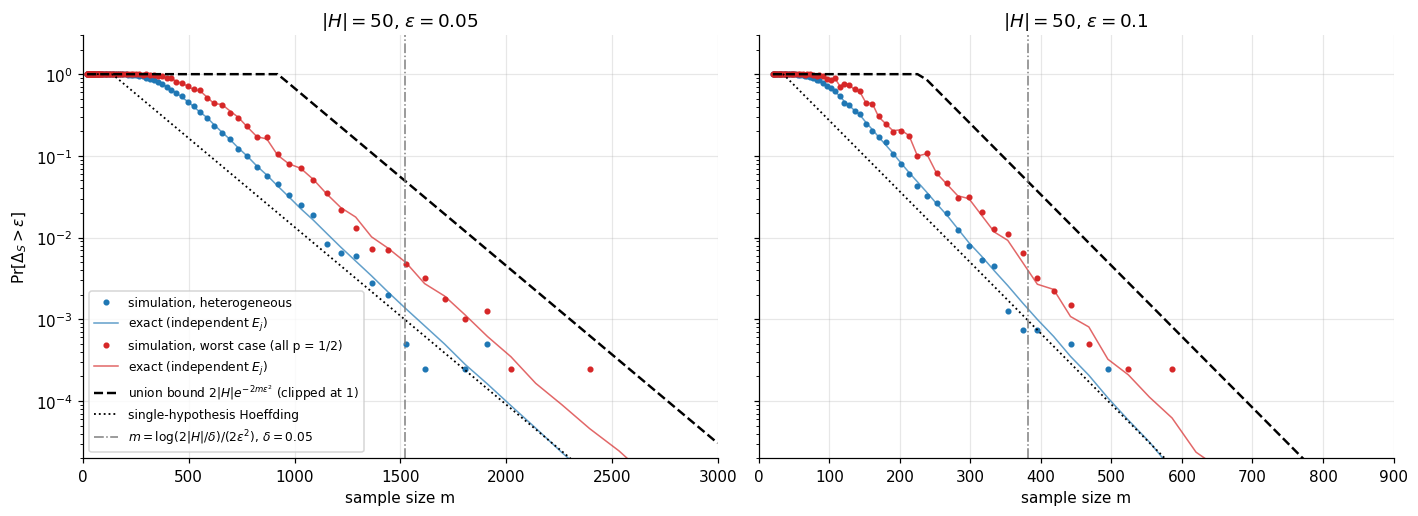

|H| = 50, epsilon = 0.05


,scenario,m,simulated Pr[Delta>eps],exact,union bound
0,heterogeneous,201,0.9948,9.9428e-01,1.0000
1,heterogeneous,495,0.4567,4.6313e-01,1.0000
2,heterogeneous,973,0.0333,3.1587e-02,0.7712
3,heterogeneous,1527,0.0005,1.3427e-03,0.0483
4,heterogeneous,2023,0.0000,8.7852e-05,0.0040
5,worst case (all p = 1/2),201,0.9995,9.9982e-01,1.0000
6,worst case (all p = 1/2),495,0.7080,7.1100e-01,1.0000
7,worst case (all p = 1/2),973,0.0800,7.9980e-02,0.7712
8,worst case (all p = 1/2),1527,0.0047,4.9431e-03,0.0483
9,worst case (all p = 1/2),2023,0.0003,3.4834e-04,0.0040


In [6]:
K3 = 50
k3 = K_list.index(K3)
colors3 = {"heterogeneous": "tab:blue", "worst case (all p = 1/2)": "tab:red"}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, eps in zip(axes, (0.05, 0.1)):
    for name in scenarios:
        mc = (sim_delta[name][:, k3, :] > eps + TOL).mean(axis=1)              # estimate of Pr[Delta_S > eps]
        ax.semilogy(m_grid_uc, np.where(mc > 0, mc, np.nan), "o", ms=3, color=colors3[name], label=f"simulation, {name}")
        ax.semilogy(m_grid_uc, exact_fail[(name, eps)][:, K3 - 1], "-", lw=1, color=colors3[name], alpha=0.7,
                    label="exact (independent $E_j$)")
    ax.semilogy(m_grid_uc, np.minimum(union_bound(m_grid_uc, eps, K3), 1), "k--", lw=1.6,
                label=r"union bound $2|H|e^{-2m\epsilon^2}$ (clipped at 1)")
    ax.semilogy(m_grid_uc, np.minimum(hoeffding(m_grid_uc, eps), 1), "k:", lw=1.2, label="single-hypothesis Hoeffding")
    ax.axvline(m_sufficient(eps, 0.05, K3), color="gray", lw=1, ls="-.", label=r"$m=\log(2|H|/\delta)/(2\epsilon^2)$, $\delta=0.05$")
    ax.set_ylim(2e-5, 3); ax.set_xlim(0, 3000 if eps == 0.05 else 900)
    ax.set_xlabel("sample size m"); ax.set_title(rf"$|H|={K3}$, $\epsilon={eps}$")
axes[0].set_ylabel(r"$\Pr[\Delta_S>\epsilon]$"); axes[0].legend(loc="lower left")
plt.tight_layout(); plt.show()

eps = 0.05
rows = []
for name in scenarios:
    for m0 in [200, 500, 1000, 1500, 2000]:
        i = int(np.argmin(np.abs(m_grid_uc - m0)))
        rows.append({"scenario": name, "m": m_grid_uc[i],
                     "simulated Pr[Delta>eps]": (sim_delta[name][i, k3, :] > eps + TOL).mean(),
                     "exact": exact_fail[(name, eps)][i, K3 - 1],
                     "union bound": min(1.0, union_bound(m_grid_uc[i], eps, K3))})
print(f"|H| = {K3}, epsilon = {eps}")
display(pd.DataFrame(rows))

**Interpretation (shown here for $|\mathcal H|=50$).**
* Simulation and the exact formula agree, which validates both.
* Uniform convergence is much harder than concentration for one hypothesis: with $\epsilon=0.05$ and $m\approx 500$, the sample fails to be $\epsilon$-representative with probability about 0.46 (heterogeneous) to 0.71 (worst case), whereas a single hypothesis would fail with probability of a few percent.
* The union bound is a valid upper bound but is vacuous (≥ 1) up to $m\approx 920$. At $m\approx1521$, the sufficient size for $\delta=0.05$, the bound equals 0.05 by construction while the simulation gives about 0.005 (worst case) and 0.0005 (heterogeneous): the guarantee holds with a safety margin of one to two orders of magnitude.
* The heterogeneous class is "easier" than the worst case: hypotheses with $p$ far from $\tfrac12$ have a smaller variance and rarely deviate.
* **Where the slack comes from.** For independent, rare failure events the union bound is nearly exact ($1-(1-q)^K\approx Kq$), so here most of the slack is inherited from Hoeffding (factor ≈ 10 at $p=\tfrac12$, as in the previous experiment, and much more for low-variance hypotheses). In a real class the hypotheses are correlated — their failure events overlap — and the union bound, which counts every event separately, is even looser. Independence is a modelling simplification of the statement; correlated errors would lower the true failure probability.

### Task 4 — Effect of the size of the hypothesis class
We fix $\epsilon=0.05$ and plot $\Pr[\Delta_S>\epsilon]$ as a function of $m$ for $|\mathcal H|\in\{5,10,50,100,500\}$ in both scenarios (dashed lines: the union bound of each class). A second figure shows, for the worst case, how the failure probability depends on $|\mathcal H|$ itself at fixed $m$ (line: exact value for every $|\mathcal H|$ from 1 to 500; dots: simulation).

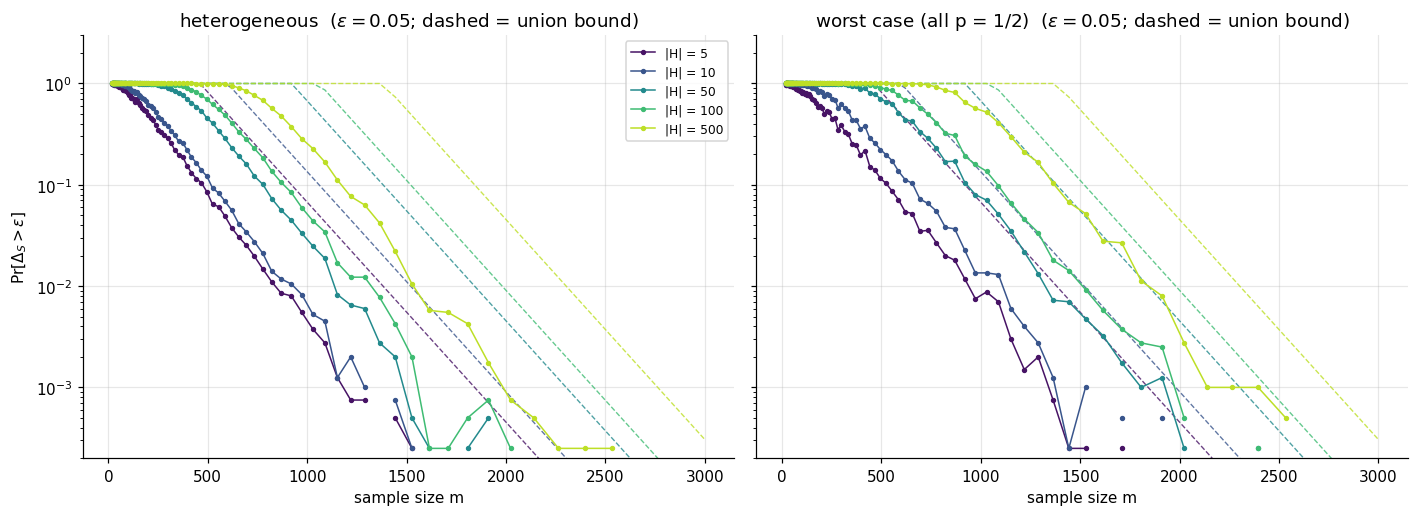

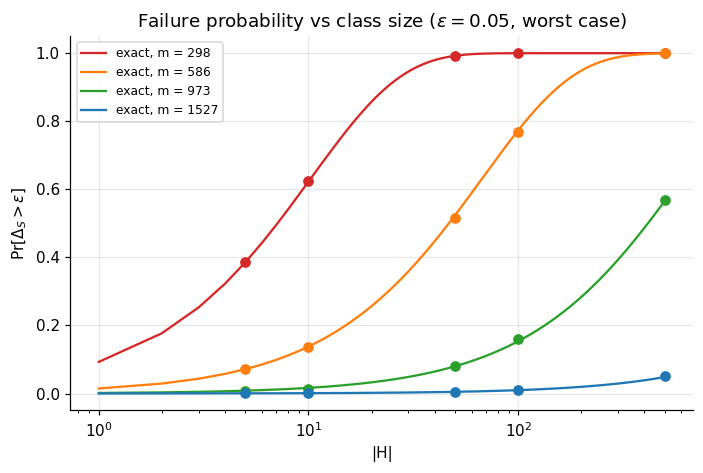

In [7]:
eps4 = 0.05
cmap = plt.cm.viridis(np.linspace(0.05, 0.9, len(K_list)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, name in zip(axes, scenarios):
    for kk, (K, c) in enumerate(zip(K_list, cmap)):
        mc = (sim_delta[name][:, kk, :] > eps4 + TOL).mean(axis=1)
        ax.semilogy(m_grid_uc, np.where(mc > 0, mc, np.nan), "o-", ms=2.5, lw=1, color=c, label=f"|H| = {K}")
        ax.semilogy(m_grid_uc, np.minimum(union_bound(m_grid_uc, eps4, K), 1), "--", lw=0.9, color=c, alpha=0.8)
    ax.set_ylim(2e-4, 3); ax.set_xlabel("sample size m"); ax.set_title(f"{name}  ($\\epsilon={eps4}$; dashed = union bound)")
axes[0].set_ylabel(r"$\Pr[\Delta_S>\epsilon]$"); axes[0].legend()
plt.tight_layout(); plt.show()

# Pr[Delta > eps] as a function of |H| for a few fixed sample sizes (worst-case scenario: exact curve + simulation)
name = "worst case (all p = 1/2)"
fig, ax = plt.subplots(figsize=(6.5, 4.4))
for m0, c in zip([300, 600, 1000, 1500], ["tab:red", "tab:orange", "tab:green", "tab:blue"]):
    i = int(np.argmin(np.abs(m_grid_uc - m0)))
    Ks = np.arange(1, K_max + 1)
    ax.semilogx(Ks, exact_fail[(name, eps4)][i], "-", color=c, label=f"exact, m = {m_grid_uc[i]}")
    ax.semilogx(K_list, [(sim_delta[name][i, kk, :] > eps4 + TOL).mean() for kk in range(len(K_list))], "o", color=c)
ax.set_xlabel("|H|"); ax.set_ylabel(r"$\Pr[\Delta_S>\epsilon]$"); ax.set_title(rf"Failure probability vs class size ($\epsilon={eps4}$, worst case)")
ax.legend(); plt.tight_layout(); plt.show()

**Interpretation.**
* **Effect of $|\mathcal H|$.** Increasing $|\mathcal H|$ makes uniform convergence *harder*: the curves are ordered and move to the right (this is forced by the nesting, since a maximum over a larger set can only be larger). At a fixed $m$ the failure probability first grows roughly proportionally to $|\mathcal H|$ and then saturates at 1 (second figure): with many hypotheses, some of them almost surely have an unrepresentative sample.
* **Does a larger class need more data? Yes, but only a little more.** To bring the failure probability below $0.05$ at $\epsilon=0.05$ the worst case needs $m\approx 694,\,822,\,1152,\,1219,\,1615$ for $|\mathcal H|=5,10,50,100,500$ (table of the next experiment): a class 100 times larger needs only about 2.3 times more data.
* **Link with $\log|\mathcal H|$.** Setting the union bound equal to $\delta$ gives $m=\dfrac{\ln|\mathcal H|+\ln(2/\delta)}{2\epsilon^2}$: a *multiplicative* factor $|\mathcal H|$ in the failure probability becomes an *additive* shift $\ln|\mathcal H|/(2\epsilon^2)$ in the sample size. Going from 5 to 500 hypotheses the predicted shift is $\ln(100)/(2\cdot0.05^2)\approx 921$; the simulation gives about 921 (worst case) and 778 (heterogeneous). The curves are therefore shifted by comparable *amounts* each time $|\mathcal H|$ is multiplied by a constant, which is the signature of a logarithmic dependence.

### Task 5 — Experimental sample complexity
For $\epsilon\in\{0.05,0.1\}$ and $\delta=0.05$ we determine, for each class size, the smallest tested $m$ such that $\Pr[\Delta_S>\epsilon]\le\delta$, and compare it with the theoretical sufficient size
$$m\ \ge\ \frac{\log(2|\mathcal H|/\delta)}{2\epsilon^2}.$$
Because the probability is estimated by Monte-Carlo, we call $m$ "reached" when the criterion holds at that $m$ **and at every larger tested $m$**; this avoids picking a lucky fluctuation right at the threshold. The grid has a resolution of about 5 %. The column *exact model* applies the same rule to the exact failure probabilities (no Monte-Carlo noise). Finally, the fitted slope of the experimental $m$ against $\ln|\mathcal H|$ is compared with the slope $1/(2\epsilon^2)$ predicted by the bound.

delta = 0.05;  grid resolution ~5 %


,scenario,eps,|H|,m_exp (simulation),m_exp (exact model),m_th = log(2|H|/delta)/(2 eps^2),m_th / m_exp
0,heterogeneous,0.05,5,586,620,1060,1.8089
1,heterogeneous,0.05,10,656,656,1199,1.8277
2,heterogeneous,0.05,50,920,920,1521,1.6533
3,heterogeneous,0.05,100,1029,1029,1659,1.6122
4,heterogeneous,0.05,500,1364,1364,1981,1.4523
5,heterogeneous,0.10,5,143,143,265,1.8531
6,heterogeneous,0.10,10,161,161,300,1.8634
7,heterogeneous,0.10,50,225,225,381,1.6933
8,heterogeneous,0.10,100,267,267,415,1.5543
9,heterogeneous,0.10,500,334,334,496,1.4850


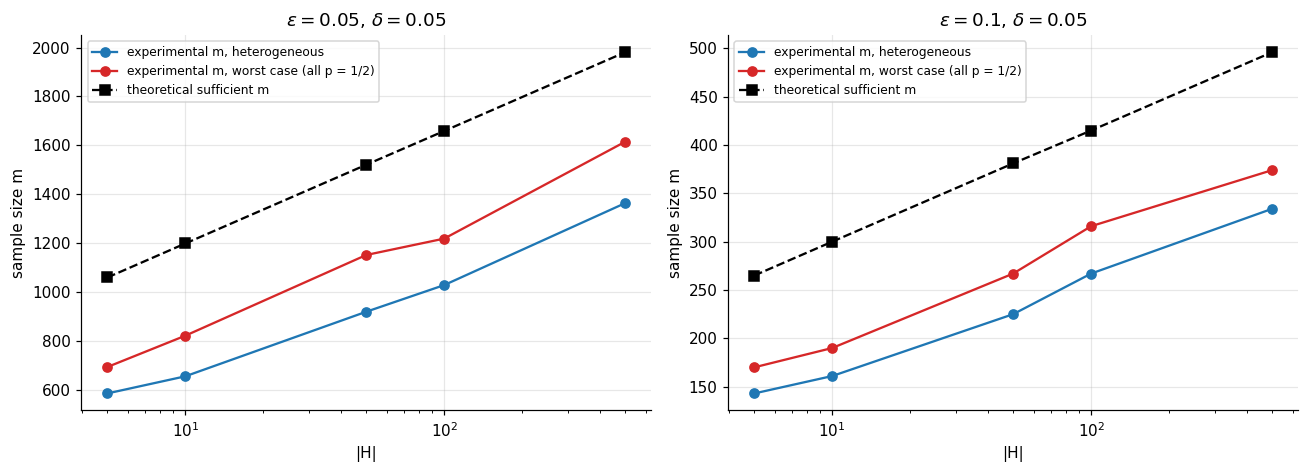

heterogeneous              eps=0.05: fitted slope of m vs ln|H| =   169.1   (theory 1/(2 eps^2) = 200.0)
heterogeneous              eps=0.1: fitted slope of m vs ln|H| =    42.4   (theory 1/(2 eps^2) = 50.0)
worst case (all p = 1/2)   eps=0.05: fitted slope of m vs ln|H| =   196.3   (theory 1/(2 eps^2) = 200.0)
worst case (all p = 1/2)   eps=0.1: fitted slope of m vs ln|H| =    46.2   (theory 1/(2 eps^2) = 50.0)


In [8]:
delta = 0.05

def smallest_stable_m(ok, m_grid):
    """Smallest tested m such that the criterion holds there AND for every larger tested m
    (protects against a lucky Monte-Carlo fluctuation right at the threshold)."""
    stable = np.logical_and.accumulate(ok[::-1])[::-1]
    return m_grid[np.argmax(stable)] if stable.any() else np.nan

rows = []
for name in scenarios:
    for eps in (0.05, 0.1):
        for kk, K in enumerate(K_list):
            mc = (sim_delta[name][:, kk, :] > eps + TOL).mean(axis=1)
            m_exp = smallest_stable_m(mc <= delta, m_grid_uc)
            m_ex = smallest_stable_m(exact_fail[(name, eps)][:, K - 1] <= delta, m_grid_uc)
            m_th = m_sufficient(eps, delta, K)
            rows.append({"scenario": name, "eps": eps, "|H|": K, "m_exp (simulation)": m_exp,
                         "m_exp (exact model)": m_ex, "m_th = log(2|H|/delta)/(2 eps^2)": m_th,
                         "m_th / m_exp": m_th / m_exp})
tab5 = pd.DataFrame(rows)
print(f"delta = {delta};  grid resolution ~5 %")
display(tab5)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=False)
for ax, eps in zip(axes, (0.05, 0.1)):
    sub = tab5[tab5.eps == eps]
    for name, c in colors3.items():
        s = sub[sub.scenario == name]
        ax.semilogx(s["|H|"], s["m_exp (simulation)"], "o-", color=c, label=f"experimental m, {name}")
    ax.semilogx(K_list, [m_sufficient(eps, delta, K) for K in K_list], "ks--", label="theoretical sufficient m")
    ax.set_xlabel("|H|"); ax.set_ylabel("sample size m"); ax.set_title(rf"$\epsilon={eps}$, $\delta={delta}$"); ax.legend()
plt.tight_layout(); plt.show()

# slope of m against ln|H|: the bound predicts 1/(2 eps^2) per unit of ln|H|
for name in scenarios:
    for eps in (0.05, 0.1):
        s = tab5[(tab5.scenario == name) & (tab5.eps == eps)]
        slope = np.polyfit(np.log(s["|H|"]), s["m_exp (simulation)"], 1)[0]
        print(f"{name:26s} eps={eps}: fitted slope of m vs ln|H| = {slope:7.1f}   (theory 1/(2 eps^2) = {1/(2*eps**2):.1f})")

In [9]:
# From uniform convergence to an ERM guarantee: |H| = 100, eps = 0.1, delta = 0.05.
K, eps, dl = 100, 0.1, 0.05
m_uc   = ceil(log(2 * K / dl) / (2 * eps**2))          # |L_S - L_D| <= eps for all h
m_apac = ceil(2 * log(2 * K / dl) / eps**2)            # = m_UC(eps/2, delta): ERM within eps of the best h in H
m_real = ceil(log(K / dl) / eps)                       # realizable case (a perfect hypothesis exists)
print(f"uniform convergence at eps      : m >= {m_uc}")
print(f"agnostic ERM (UC at eps/2)       : m >= {m_apac}   (= 4 x the previous one, up to rounding)")
print(f"realizable PAC (L_D(h*) = 0)     : m >= {m_real}")

uniform convergence at eps      : m >= 415
agnostic ERM (UC at eps/2)       : m >= 1659   (= 4 x the previous one, up to rounding)
realizable PAC (L_D(h*) = 0)     : m >= 77


**Interpretation.**
* In all 20 settings the experimental sample size is **below** the theoretical one: the ratio $m_{th}/m_{exp}$ is between 1.2 and 1.9. The bound is a *sufficient* guarantee (it is never violated), not the exact minimum.
* Why it overshoots. The bound must work for **every** distribution, **every** vector of true risks and **any** dependence between hypotheses, so it is derived with worst-case tools: Hoeffding ignores the variance and loses a polynomial prefactor, the union bound adds failure events that may coincide, and the sample size is rounded up. The slack is smallest in the worst case ($p_j=\tfrac12$: ratio 1.2–1.6) and larger for the heterogeneous class (1.5–1.9), where many hypotheses have low variance. The theoretical value is the *same* in both scenarios, whereas the true requirement depends on the actual $p_j$.
* The **dependence on $|\mathcal H|$ is logarithmic with the predicted slope**: the fitted slope of $m_{exp}$ versus $\ln|\mathcal H|$ is 196 and 46 in the worst case against the theoretical 200 and 50 (98 % and 92 %), and 169 and 42 for the heterogeneous class. The *intercept* is overestimated by the bound, the *growth rate* is almost exact in the worst case.
* Halving $\epsilon$ from 0.1 to 0.05 multiplies the required sample size by about 4 (e.g. 316 → 1219 for $|\mathcal H|=100$, worst case), as predicted by the $1/\epsilon^2$ dependence.
* **Consequence for ERM.** To guarantee that ERM is within $\epsilon$ of the best hypothesis of $\mathcal H$, a representative sample at accuracy $\epsilon/2$ is needed (the empirical-to-true transition is paid twice). For $|\mathcal H|=100$, $\epsilon=0.1$, $\delta=0.05$ this means 1659 samples instead of 415 — a factor 4 again — whereas the realizable case, where a perfect hypothesis exists, needs only 77 (the dependence on the accuracy drops from $1/\epsilon^2$ to $1/\epsilon$).

---
# Part II — Simulating No-Free-Lunch

**Setting.** The domain is $\mathcal X=\{1,\dots,N\}$ (indexed from 0 in the code) with the uniform distribution. In every repetition a **new target** $f:\mathcal X\to\{0,1\}$ is drawn with i.i.d. $\mathrm{Bernoulli}(\tfrac12)$ labels — a completely arbitrary labelling — and the learner receives $m$ i.i.d. uniform inputs with their labels. The learner **memorises**: it predicts the observed label on every seen input and, on an unseen input, a default value (0 for the learner of the statement). Its true risk is computed exactly over the whole domain,
$$L_D(A(S))=\frac1N\sum_{x\in\mathcal X}\mathbb 1[A(S)(x)\ne f(x)].$$

The function below simulates this for many repetitions. It really builds the lookup table of the learner, and evaluates **three rules for unseen inputs** (always 0, always 1, a fair coin) on exactly the same targets and samples, so that they can be compared without noise from different draws. It is run once on a grid of $(N,m)$ with $m=cN$.

In [10]:
def simulate_memorizer(N, m, R, pi=0.5):
    """R independent learning tasks on X = {0..N-1} with D uniform.
    Target: f(x) ~ Bernoulli(pi) independently for every x  (pi = 1/2: completely random target).
    Learner: memorise the labels of the inputs it has seen; for unseen inputs three rules are evaluated on
    exactly the same (f, S) pairs:  'zero' (the learner of the statement), 'one', 'random' (fair coin).
    Returns, per repetition, the fraction of unseen inputs and the true risk L_D(A(S)) over the whole domain."""
    f = (rng.random((R, N)) < pi).astype(np.int8)                    # one random target per repetition
    x = rng.integers(0, N, size=(R, m), dtype=np.int32)              # S ~ D^m : m uniform inputs ...
    rows = np.arange(R)[:, None]
    table = np.full((R, N), -1, dtype=np.int8)                       # -1 = "never observed"
    table[rows, x] = f[rows, x]                                      # ... whose labels f(x_i) the learner stores
    unseen = table < 0
    out = {"unseen": unseen.mean(axis=1)}
    default = {"zero": np.zeros((R, N), np.int8), "one": np.ones((R, N), np.int8),
               "random": rng.integers(0, 2, size=(R, N), dtype=np.int8)}
    for name, d in default.items():
        pred = np.where(unseen, d, table)                            # seen: stored label; unseen: default rule
        out["risk_" + name] = (pred != f).mean(axis=1)               # L_D(A(S)) = (1/N) sum_x 1[A(S)(x) != f(x)]
    return out

N_list = [10, 50, 200, 1000]
c_list = [0.1, 0.25, 0.5, 1, 1.5, 2, 3, 4]       # m = c * N : from "far fewer samples than points" to "many times N"
R_nfl = 2000
nfl = {}
for N in N_list:
    for c in c_list:
        m = max(1, int(round(c * N)))
        nfl[(N, m)] = simulate_memorizer(N, m, R_nfl)
print("simulated", len(nfl), "(N, m) settings with", R_nfl, "repetitions each")

simulated 32 (N, m) settings with 2000 repetitions each


### Task 6 — Seen and unseen inputs
For each $(N,m)$ we measure the fraction of inputs never observed in the sample and compare it with the probability that a fixed point is unseen, $(1-\tfrac1N)^m$.

**Why this is also the expected fraction.** Let $U_x=\mathbb 1[x\text{ is never sampled}]$. The $m$ draws are independent and each misses $x$ with probability $1-\tfrac1N$, hence $\mathbb E[U_x]=\Pr[x\text{ unseen}]=(1-\tfrac1N)^m$. The unseen fraction is $\frac1N\sum_{x}U_x$ and by linearity of expectation
$$\mathbb E\Big[\frac1N\sum_{x\in\mathcal X}U_x\Big]=\frac1N\sum_{x\in\mathcal X}\mathbb E[U_x]=\Big(1-\frac1N\Big)^m .$$
(The $U_x$ are *not* independent, but linearity of expectation does not need independence.) Note also that $(1-\tfrac1N)^m\approx e^{-m/N}$ for large $N$.

,N,m,m/N,simulated E[unseen],theory (1-1/N)^m,std error,z = (sim-theory)/se
0,10,1,0.10,0.9000,0.9000,0.0000,NaN
1,10,2,0.20,0.8090,0.8100,0.0006,-1.6445
2,10,5,0.50,0.5904,0.5905,0.0016,-0.0245
3,10,10,1.00,0.3491,0.3487,0.0022,0.1894
4,10,15,1.50,0.2080,0.2059,0.0022,0.9177
5,10,20,2.00,0.1216,0.1216,0.0019,0.0120
6,10,30,3.00,0.0428,0.0424,0.0014,0.2998
7,10,40,4.00,0.0144,0.0148,0.0008,-0.3931
8,50,5,0.10,0.9038,0.9039,0.0002,-0.5425
9,50,12,0.24,0.7850,0.7847,0.0004,0.5882


largest |z| over all settings: 1.64


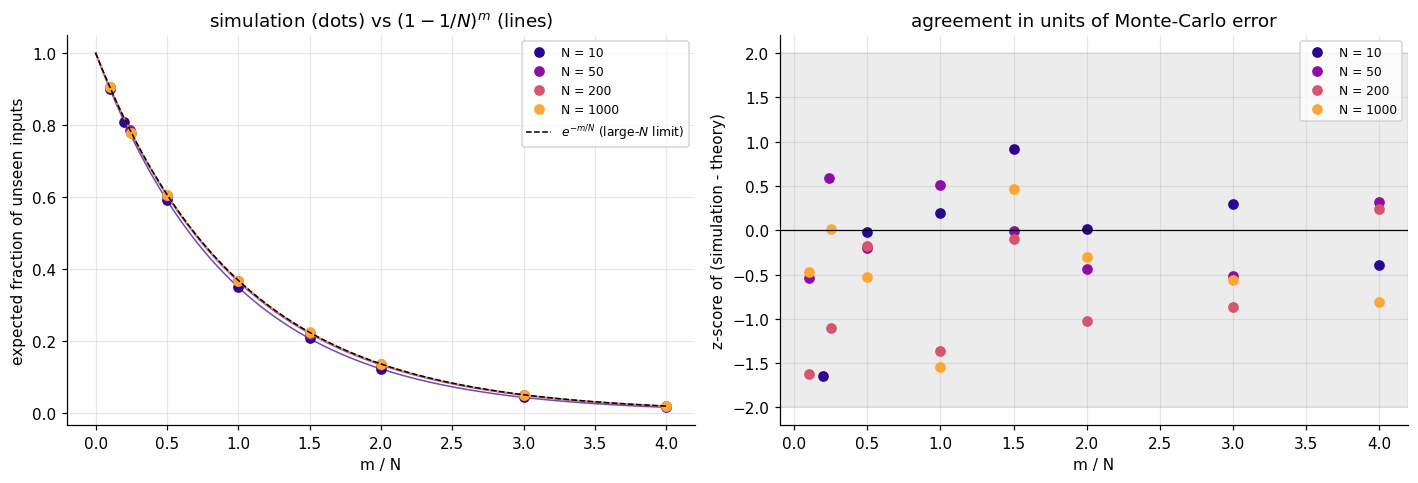

In [11]:
rows = []
for (N, m), r in nfl.items():
    th = (1 - 1 / N) ** m
    se = r["unseen"].std(ddof=1) / np.sqrt(R_nfl)
    rows.append({"N": N, "m": m, "m/N": m / N, "simulated E[unseen]": r["unseen"].mean(), "theory (1-1/N)^m": th,
                 "std error": se, "z = (sim-theory)/se": (r["unseen"].mean() - th) / se if se > 1e-12 else np.nan})   # se = 0 when m = 1 (exactly one seen point)
tab6 = pd.DataFrame(rows)
display(tab6.round(4))
print("largest |z| over all settings:", tab6["z = (sim-theory)/se"].abs().max().round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cols = dict(zip(N_list, plt.cm.plasma(np.linspace(0.05, 0.8, len(N_list)))))
xx = np.linspace(0, 4, 200)
for N in N_list:
    s = tab6[tab6.N == N]
    axes[0].plot(xx, (1 - 1 / N) ** (xx * N), "-", color=cols[N], lw=1, alpha=0.7)
    axes[0].plot(s["m/N"], s["simulated E[unseen]"], "o", color=cols[N], label=f"N = {N}")
    axes[1].plot(s["m/N"], s["z = (sim-theory)/se"], "o", color=cols[N], label=f"N = {N}")
axes[0].plot(xx, np.exp(-xx), "k--", lw=1, label=r"$e^{-m/N}$ (large-$N$ limit)")
axes[0].set_xlabel("m / N"); axes[0].set_ylabel("expected fraction of unseen inputs")
axes[0].set_title(r"simulation (dots) vs $(1-1/N)^m$ (lines)"); axes[0].legend()
axes[1].axhline(0, color="k", lw=0.8); axes[1].axhspan(-2, 2, color="gray", alpha=0.15)
axes[1].set_xlabel("m / N"); axes[1].set_ylabel("z-score of (simulation - theory)"); axes[1].set_title("agreement in units of Monte-Carlo error")
axes[1].legend(); plt.tight_layout(); plt.show()

**Interpretation.**
* The simulated fractions agree with $(1-1/N)^m$ for every $N$ and $m$: the z-scores are all inside $\pm 2$ (largest $|z|\approx1.6$) and are not systematically positive or negative. The case $m=1$ has a standard error of exactly 0 because exactly one point is seen in every repetition, so its z-score is undefined (shown as NaN); the simulated and theoretical values are identical.
* The unseen fraction depends on $N$ and $m$ essentially through the ratio $m/N$ (all dots follow nearly the same curve $e^{-m/N}$). With $m=N$ samples, **35–37 % of the domain is still unseen**; one needs $m\approx 2.3\,N$ samples to leave only 10 % unseen and $m\approx 4N$ for under 2 %. Because the sample is a draw *with repetition*, even $m=N$ samples do not cover the domain.

### Task 7 — Error on unseen inputs
**Derivation.** Fix $x\in\mathcal X$ and look at the event "the learner errs at $x$".
* If $x$ **was seen**, the learner returns the stored label, which is the true label $f(x)$: no error (the labels are noise-free).
* If $x$ is **unseen**, the learner predicts 0 and errs exactly when $f(x)=1$. Whether $x$ is unseen depends only on the sampled *inputs*, while $f(x)$ is an independent $\mathrm{Bernoulli}(\tfrac12)$ variable that the learner never observed, so
$$\Pr[\text{error at }x]=\Pr[x\text{ unseen}]\cdot\Pr[f(x)=1]=\tfrac12\Big(1-\tfrac1N\Big)^m .$$
By linearity of expectation over $x$:
$$\mathbb E[L_D(A(S))]=\frac1N\sum_{x}\Pr[\text{error at }x]=\frac12\Big(1-\frac1N\Big)^m .$$

We now check this formula against the simulation of the full learner (random target, random sample, exact risk over the domain), reporting the standard error and a z-score for every $(N,m)$.

,N,m,simulated E[L_D],theory 0.5(1-1/N)^m,std error,z
0,10,1,0.4465,0.4500,0.0033,-1.0748
1,10,2,0.4136,0.4050,0.0032,2.6499
2,10,5,0.2935,0.2952,0.0029,-0.6175
3,10,10,0.1746,0.1743,0.0024,0.1077
4,10,15,0.1034,0.1029,0.0020,0.2288
5,10,20,0.0594,0.0608,0.0016,-0.8627
6,10,30,0.0211,0.0212,0.0010,-0.0987
7,10,40,0.0072,0.0074,0.0006,-0.2404
8,50,5,0.4507,0.4520,0.0015,-0.8495
9,50,12,0.3929,0.3924,0.0014,0.3724


largest |z|: 2.65    fraction of |z| < 2: 0.94


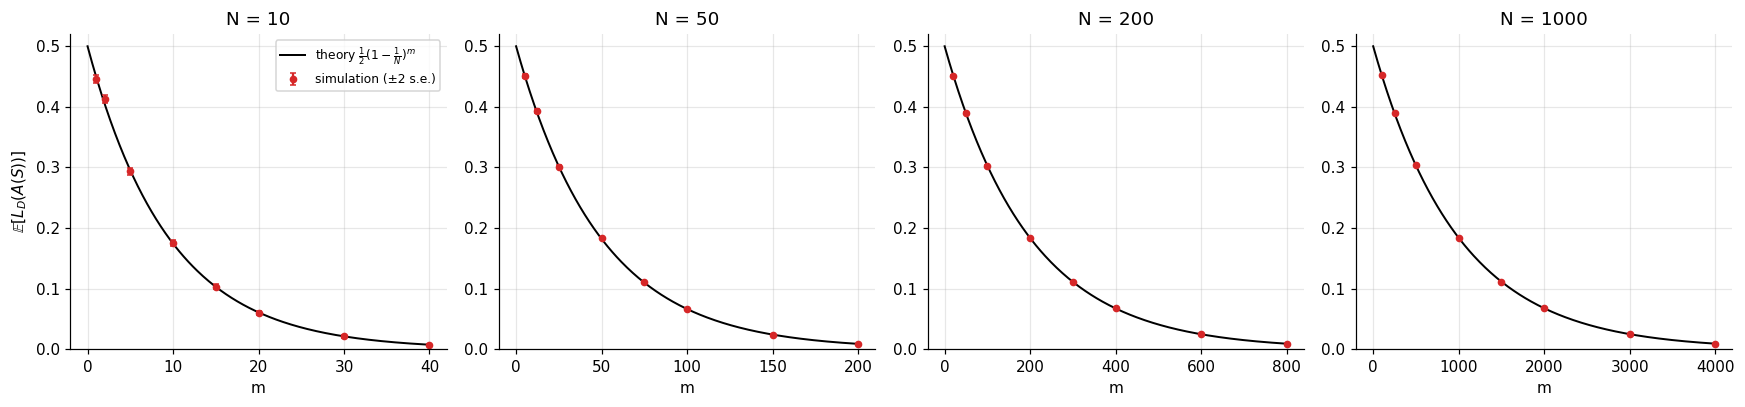

In [12]:
rows = []
for (N, m), r in nfl.items():
    th = 0.5 * (1 - 1 / N) ** m
    se = r["risk_zero"].std(ddof=1) / np.sqrt(R_nfl)
    rows.append({"N": N, "m": m, "simulated E[L_D]": r["risk_zero"].mean(), "theory 0.5(1-1/N)^m": th,
                 "std error": se, "z": (r["risk_zero"].mean() - th) / se})
tab7 = pd.DataFrame(rows)
display(tab7.round(4))
print("largest |z|:", tab7["z"].abs().max().round(2), "   fraction of |z| < 2:", (tab7["z"].abs() < 2).mean().round(2))

fig, axes = plt.subplots(1, len(N_list), figsize=(16, 3.8))
for ax, N in zip(axes, N_list):
    s = tab7[tab7.N == N]
    mm = np.linspace(0, 4 * N, 300)
    ax.plot(mm, 0.5 * (1 - 1 / N) ** mm, "k-", lw=1.3, label=r"theory $\frac{1}{2}(1-\frac{1}{N})^m$")
    ax.errorbar(s["m"], s["simulated E[L_D]"], yerr=2 * s["std error"], fmt="o", color="tab:red", ms=4, capsize=2,
                label="simulation (±2 s.e.)")
    ax.set_title(f"N = {N}"); ax.set_xlabel("m"); ax.set_ylim(0, 0.52)
axes[0].set_ylabel(r"$\mathbb{E}[L_D(A(S))]$"); axes[0].legend()
plt.tight_layout(); plt.show()

**Interpretation.** The simulation reproduces $\tfrac12(1-\tfrac1N)^m$ for all four domain sizes: 30 of the 32 settings lie within two standard errors and the largest deviation is 2.65 standard errors, which is what Monte-Carlo noise alone produces for 32 comparisons. The risk starts at $\tfrac12$ (a learner that has seen nothing is a coin flip) and decays only as the *unseen mass* decays, i.e. like $e^{-m/N}$. The learner is perfect on what it has seen and **exactly at chance on what it has not**: memorisation does not generalize at all beyond the observed inputs. To reach $\mathbb E[L_D]\le\varepsilon$ one needs $m\approx N\ln\frac{1}{2\varepsilon}$, a sample size that **grows linearly with the size of the domain**.

### Task 8 — Changing the prediction on unseen inputs
The three rules (always 0, always 1, fair coin) are compared on **identical** random targets and samples ($N=100$). Under uniformly random targets the theory predicts the same expected risk $\tfrac12(1-\tfrac1N)^m$ for all of them, because $\Pr[f(x)=1\mid x\text{ unseen}]=\tfrac12$ whatever the learner guesses. A paired comparison (difference of the two rules on the same draws) removes most of the noise.

The right panel then drops the assumption of *uniformly* random targets: labels are drawn $\mathrm{Bernoulli}(\pi)$ with $\pi$ the probability of a 1. Writing $q=(1-\tfrac1N)^m$ for the expected unseen fraction, the rules have expected risks $\pi q$ (always 0), $(1-\pi)q$ (always 1) and $q/2$ (coin). The value $\pi=\tfrac12$ is the completely random case.

,m,theory 0.5(1-1/N)^m,always 0,always 1,random coin,(0) - (1),s.e. of diff
0,0,0.5000,0.4993,0.5007,0.4996,-0.0014,0.0014
1,10,0.4522,0.4522,0.4524,0.4532,-0.0002,0.0014
2,25,0.3889,0.3889,0.3889,0.3892,0.0000,0.0012
3,50,0.3025,0.3037,0.3009,0.3033,0.0028,0.0011
4,100,0.1830,0.1826,0.1835,0.1828,-0.0009,0.0009
5,200,0.0670,0.0671,0.0666,0.0669,0.0005,0.0005
6,300,0.0245,0.0241,0.0247,0.0245,-0.0005,0.0003
7,500,0.0033,0.0033,0.0033,0.0033,0.0000,0.0001


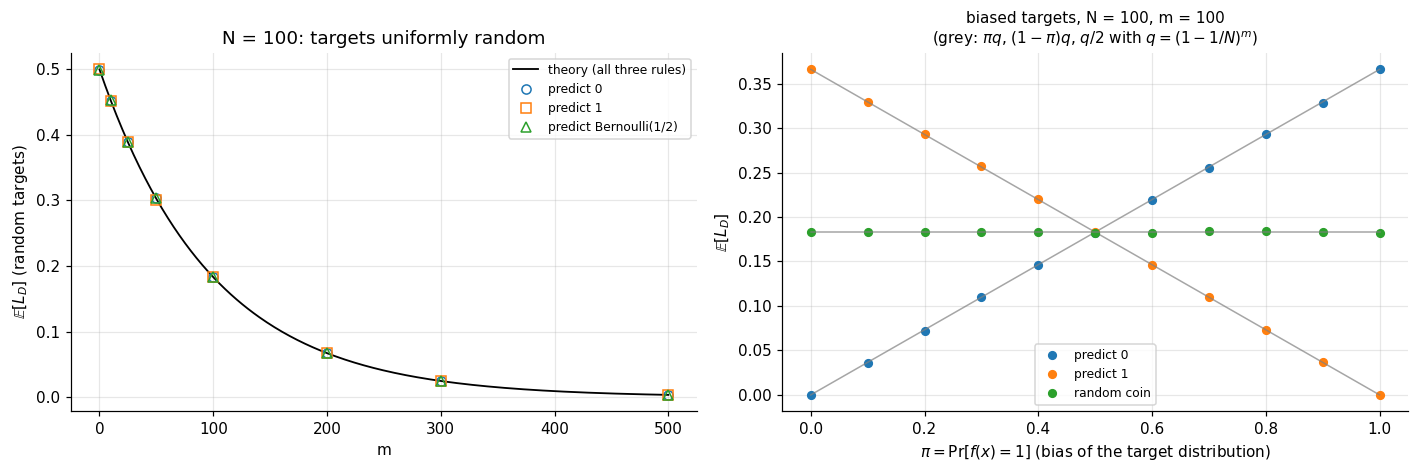

In [13]:
N8, R8 = 100, 5000
m8 = [0, 10, 25, 50, 100, 200, 300, 500]
res8 = {m: simulate_memorizer(N8, m, R8) for m in m8}

rows = []
for m in m8:
    r = res8[m]
    d = r["risk_zero"] - r["risk_one"]                      # paired difference (same f and S for both rules)
    rows.append({"m": m, "theory 0.5(1-1/N)^m": 0.5 * (1 - 1 / N8) ** m,
                 "always 0": r["risk_zero"].mean(), "always 1": r["risk_one"].mean(), "random coin": r["risk_random"].mean(),
                 "(0) - (1)": d.mean(), "s.e. of diff": d.std(ddof=1) / np.sqrt(R8)})
tab8 = pd.DataFrame(rows)
display(tab8.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
mm = np.linspace(0, 500, 300)
axes[0].plot(mm, 0.5 * (1 - 1 / N8) ** mm, "k-", lw=1.2, label="theory (all three rules)")
for key, lab, mk in [("always 0", "predict 0", "o"), ("always 1", "predict 1", "s"), ("random coin", "predict Bernoulli(1/2)", "^")]:
    axes[0].plot(tab8["m"], tab8[key], mk, ms=6, mfc="none", label=lab)
axes[0].set_xlabel("m"); axes[0].set_ylabel(r"$\mathbb{E}[L_D]$ (random targets)"); axes[0].set_title(f"N = {N8}: targets uniformly random")
axes[0].legend()

# Same experiment with biased targets: f(x) ~ Bernoulli(pi). pi = 1/2 is the completely random case.
N_b, m_b, R_b = 100, 100, 3000
pis = np.linspace(0, 1, 11)
res_pi = {pi: simulate_memorizer(N_b, m_b, R_b, pi=pi) for pi in pis}
q = (1 - 1 / N_b) ** m_b
for key, lab, th in [("risk_zero", "predict 0", pis * q), ("risk_one", "predict 1", (1 - pis) * q), ("risk_random", "random coin", np.full_like(pis, q / 2))]:
    axes[1].plot(pis, [res_pi[pi][key].mean() for pi in pis], "o", ms=5, label=lab)
    axes[1].plot(pis, th, "-", lw=1, color="gray", alpha=0.7)
axes[1].set_xlabel(r"$\pi = \Pr[f(x)=1]$ (bias of the target distribution)"); axes[1].set_ylabel(r"$\mathbb{E}[L_D]$")
axes[1].set_title(f"biased targets, N = {N_b}, m = {m_b}\n(grey: $\\pi q$, $(1-\\pi)q$, $q/2$ with $q=(1-1/N)^m$)", fontsize=10); axes[1].legend()
plt.tight_layout(); plt.show()

**Interpretation.**
* **With completely random targets no rule outperforms the others.** The three columns coincide with the theoretical value, and the paired differences "always 0 − always 1" are within noise (at most 0.003, about 2.5 standard errors for one of the eight values of $m$, otherwise below 2).
* **Each rule wins somewhere.** On biased targets the picture changes: for $\pi=0$ ("always 0" is right everywhere) predicting 0 makes no error while predicting 1 errs on every unseen point (≈ 0.37 here); for $\pi=1$ the roles are reversed; the coin is always in the middle. The lines cross exactly at $\pi=\tfrac12$, so averaging over all $2^N$ labellings gives all rules the same risk. A rule that is better on some targets must be worse on others.
* **Relation to No-Free-Lunch.** For *any* learner $A$ (deterministic or randomised), the prediction on an unseen $x$ is a function of the seen examples only, and $f(x)$ is independent of them, so $\Pr[A(S)(x)\ne f(x)\mid x\text{ unseen}]=\tfrac12$ whatever $A$ does. Hence $\mathbb E[L_D(A(S))]\ge\tfrac12(1-\tfrac1N)^m$ for every learner, with equality for every learner that fits the observed labels. No learner can do better than chance on unseen inputs when the target is arbitrary: the training sample carries no information about them. A rule such as "predict 0" looks good only if one *assumes* something about the target (here $\pi<\tfrac12$) — that assumption is a prior, not something the data provide.

---
# Part III — Introducing prior knowledge

**Setting.** Same domain $\mathcal X=\{1,\dots,N\}$ and uniform $D$, but now the target is a **threshold** $f_\theta(x)=\mathbb 1[x>\theta]$ with $\theta$ uniform in $\{1,\dots,N-1\}$, and the learner searches the class of thresholds
$$\mathcal H=\{h_t(x)=\mathbb 1[x>t]:\ t=1,\dots,N-1\},\qquad |\mathcal H|=N-1 ,$$
using **ERM**. The target belongs to $\mathcal H$ (realizable case), so there are always hypotheses with zero empirical risk.

**Facts used in the code.**
* $h_t$ and $f_\theta$ disagree exactly on the $|t-\theta|$ points between $t$ and $\theta$, so $L_D(h_t)=|t-\theta|/N$ over the whole domain.
* ERM does not say which minimiser to return. The consistent thresholds form an interval between the largest sample point labelled 0 and the smallest one labelled 1. We report two tie-breaking rules: a **random** consistent threshold, and an **adversarial ("worst") ERM** that returns the consistent threshold farthest from $\theta$. Guarantees valid for any ERM must hold for the second one.
* Since $\mathcal H$ is finite and realizable, with probability at least $1-\delta$ every consistent hypothesis satisfies $L_D(h_S)\le\dfrac{\ln(|\mathcal H|/\delta)}{m}$.

The ERM is vectorised over repetitions (cumulative counts of labelled points) and checked against a brute-force loop on a small example.

In [14]:
def erm_thresholds(x, y, N):
    """ERM over H = {h_t(x) = 1[x > t] : t = 1..N-1}, for R independent samples at once.
    x, y : (R, m) integer arrays (x in {1..N}, y in {0,1}).
    Returns the boolean (R, N-1) mask of ALL empirical-risk minimisers (column t-1 <-> threshold t)."""
    R, m = x.shape
    idx = (np.arange(R)[:, None] * N + (x - 1)).ravel()
    c1 = np.bincount(idx, weights=y.ravel(), minlength=R * N).reshape(R, N)       # label-1 points at each x
    c0 = np.bincount(idx, minlength=R * N).reshape(R, N) - c1                      # label-0 points at each x
    cum1 = np.cumsum(c1, axis=1)[:, : N - 1]                                       # label 1 with x <= t  (h_t predicts 0: mistake)
    cum0 = np.cumsum(c0, axis=1)[:, : N - 1]
    n_err = cum1 + (c0.sum(axis=1, keepdims=True) - cum0)                          # + label 0 with x > t (h_t predicts 1: mistake)
    return n_err == n_err.min(axis=1, keepdims=True)                              # empirical risk = n_err / m

def simulate_threshold(N, m, R):
    """Structured targets f_theta(x) = 1[x > theta], theta uniform on {1..N-1}; ERM over thresholds.
    Two tie-breaking rules among the minimisers (the ERM rule does not specify one):
       'random' : uniformly among all ERM thresholds,
       'worst'  : adversarially, the ERM threshold that is farthest from theta.
    True risk of h_t against f_theta over the whole domain: |t - theta| / N  (they disagree on exactly |t-theta| points)."""
    x = rng.integers(1, N + 1, size=(R, m))                      # S ~ D^m (uniform on {1..N})
    theta = rng.integers(1, N, size=R)                            # one structured target per repetition
    y = (x > theta[:, None]).astype(np.int64)                    # labels given by the target
    mask = erm_thresholds(x, y, N)
    t_all = np.arange(1, N)
    t_rand = np.argmax(rng.random(mask.shape) * mask, axis=1) + 1
    dist_worst = np.where(mask, np.abs(t_all[None, :] - theta[:, None]), -1).max(axis=1)
    return {"risk_random": np.abs(t_rand - theta) / N, "risk_worst": dist_worst / N}

def simulate_random_target_threshold_erm(N, m, R):
    """Mismatched prior: the target is a completely random labelling, but the learner still does ERM over thresholds."""
    f = rng.integers(0, 2, size=(R, N))
    x = rng.integers(1, N + 1, size=(R, m))
    y = f[np.arange(R)[:, None], x - 1]
    mask = erm_thresholds(x, y, N)
    t = np.argmax(rng.random(mask.shape) * mask, axis=1) + 1
    pred = (np.arange(1, N + 1)[None, :] > t[:, None]).astype(int)
    return {"risk_random": (pred != f).mean(axis=1)}

# sanity check of the ERM implementation against a brute-force loop on a tiny example
N_chk, m_chk = 12, 7
xs = rng.integers(1, N_chk + 1, size=(1, m_chk)); th_chk = 5
ys = (xs > th_chk).astype(np.int64)
brute = [np.sum((xs[0] > t).astype(int) != ys[0]) for t in range(1, N_chk)]
fast = erm_thresholds(xs, ys, N_chk)[0]
assert np.array_equal(fast, np.array(brute) == min(brute)); print("ERM check passed; consistent thresholds:", np.flatnonzero(fast) + 1, "(target theta = 5)")

ERM check passed; consistent thresholds: [4 5 6 7] (target theta = 5)


### Task 9 — Learning with a matching inductive bias
For the same $(N,m)$ grid as in the random-target experiment we generate a threshold target, draw a sample, run ERM and compute the exact true risk over $\mathcal X$; $\mathbb E[L_D(h_S)]$ is estimated over many repetitions and set next to the random-target risk from Part II. In the figure both are shown against $m$ on log–log axes.

,N,m,threshold ERM (random tie),s.e.,threshold ERM (worst tie),random target (simulation),random target (theory)
0,10,1,0.2067,0.0040,0.4243,0.4465,0.4500
1,10,2,0.1589,0.0034,0.3174,0.4136,0.4050
2,10,5,0.0787,0.0022,0.1592,0.2935,0.2952
3,10,10,0.0364,0.0014,0.0744,0.1746,0.1743
4,10,15,0.0215,0.0011,0.0424,0.1034,0.1029
5,10,20,0.0115,0.0008,0.0235,0.0594,0.0608
6,10,30,0.0040,0.0004,0.0084,0.0211,0.0212
7,10,40,0.0012,0.0002,0.0028,0.0072,0.0074
8,50,5,0.0937,0.0021,0.2035,0.4507,0.4520
9,50,12,0.0470,0.0012,0.0960,0.3929,0.3924


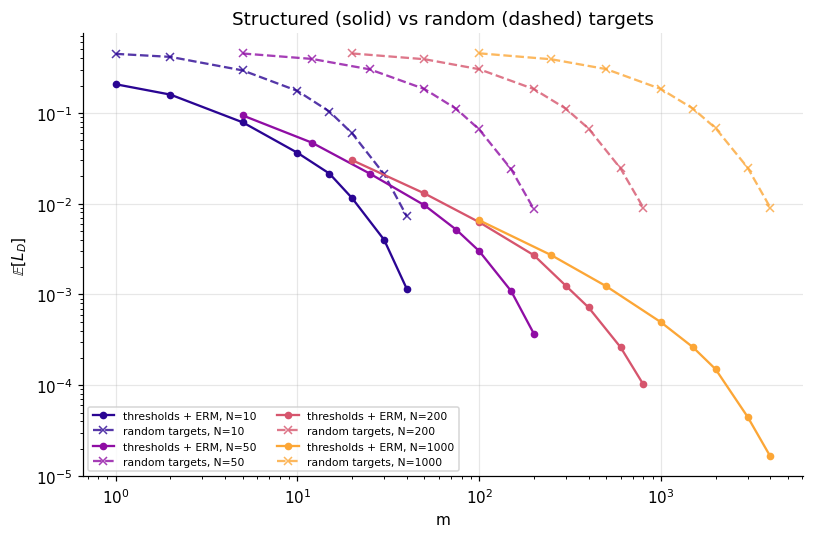

In [15]:
R3 = 2000
thr = {}
for (N, m) in nfl:                              # same (N, m) grid as the random-target experiment
    thr[(N, m)] = simulate_threshold(N, m, R3)

rows = []
for (N, m) in nfl:
    a, b = thr[(N, m)]["risk_random"], thr[(N, m)]["risk_worst"]
    rows.append({"N": N, "m": m, "threshold ERM (random tie)": a.mean(), "s.e.": a.std(ddof=1) / np.sqrt(R3),
                 "threshold ERM (worst tie)": b.mean(), "random target (simulation)": nfl[(N, m)]["risk_zero"].mean(),
                 "random target (theory)": 0.5 * (1 - 1 / N) ** m})
tab9 = pd.DataFrame(rows)
display(tab9.round(4))

fig, ax = plt.subplots(figsize=(7.5, 5))
for N in N_list:
    s = tab9[tab9.N == N]
    ax.loglog(s["m"], s["threshold ERM (random tie)"], "o-", color=cols[N], ms=4, label=f"thresholds + ERM, N={N}")
    ax.loglog(s["m"], s["random target (simulation)"], "x--", color=cols[N], ms=5, alpha=0.8, label=f"random targets, N={N}")
ax.set_xlabel("m"); ax.set_ylabel(r"$\mathbb{E}[L_D]$"); ax.set_title("Structured (solid) vs random (dashed) targets"); ax.legend(ncol=2, fontsize=7)
plt.tight_layout(); plt.show()

**Interpretation.**
* With the threshold bias the expected risk is tiny even though most of the domain is unseen: for $N=200$ and $m=200$ (the same $m=N$ for which the random-target learner still errs on 18 % of the domain) it is 0.0027, about 70 times smaller; for $N=1000$, $m=1000$ it is about 0.0005, more than 300 times smaller.
* The two experiments have different scalings. The random-target risk is a function of $m/N$ and decays like $e^{-m/N}$, so the curves for different $N$ **fan out**: a bigger domain needs proportionally more data. The threshold risk behaves like $1/m$ and the curves for different $N$ nearly **superimpose** (as long as $m$ is below $N$; once most of a small domain has been observed, as for $N=10$, the risk drops faster): the number of samples needed does not depend on how many points the domain contains.
* The tie-breaking matters only by a constant: the adversarial ERM has about twice the risk of the random one, with the same $1/m$ behaviour.

### Task 10 — Random targets vs. structured targets
The figure compares, for $N=100$ and a fine grid of $m$:
* **(a)** completely random targets with the memorisation learner (simulation and theory $\tfrac12(1-\tfrac1N)^m$);
* **(b)** threshold targets learned by ERM over thresholds;
* an additional control curve: **random targets learned by ERM over thresholds**, i.e. the same learner with the *wrong* prior.

The second figure uses the finite-class guarantee to explain the difference: with probability $\ge1-\delta$ the risk of any consistent hypothesis is at most $\ln(|\mathcal H|/\delta)/m$, where $\ln|\mathcal H|=N\ln 2$ for "all labellings" and $\ln|\mathcal H|=\ln(N-1)$ for thresholds. The 95 % quantile of the simulated risk is shown against these two bounds. Finally, a small table gives the number of samples needed to reach $\mathbb E[L_D]\le 0.05$ as $N$ grows.

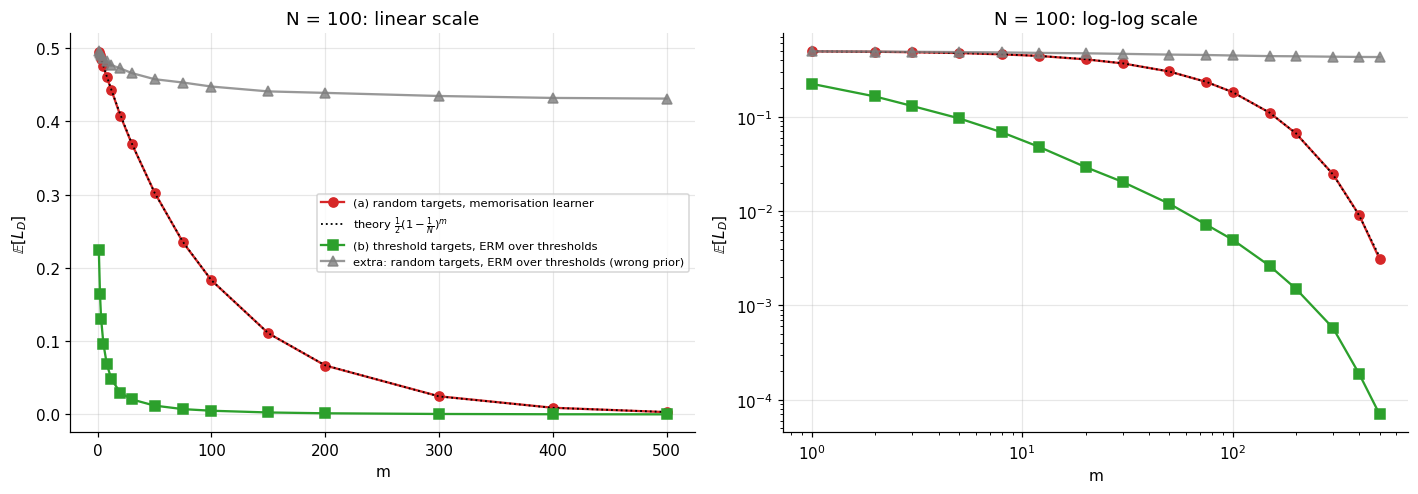

,m,(a) random targets,(b) thresholds,extra (wrong prior)
0,1,0.4951,0.2240,0.4957
1,2,0.4905,0.1645,0.4933
2,3,0.4847,0.1304,0.4902
3,5,0.4753,0.0965,0.4864
4,8,0.4600,0.0686,0.4823
5,12,0.4430,0.0482,0.4769
6,20,0.4073,0.0293,0.4723
7,30,0.3692,0.0204,0.4659
8,50,0.3029,0.0120,0.4576
9,75,0.2347,0.0072,0.4530


In [16]:
N10, R10 = 100, 4000
m10 = [1, 2, 3, 5, 8, 12, 20, 30, 50, 75, 100, 150, 200, 300, 400, 500]
rnd = {m: simulate_memorizer(N10, m, R10) for m in m10}                       # (a) random targets, memorisation
thr10 = {m: simulate_threshold(N10, m, R10) for m in m10}                      # (b) threshold targets, threshold ERM
mis = {m: simulate_random_target_threshold_erm(N10, m, R10) for m in m10}      # extra: random targets, threshold ERM

curve_a = np.array([rnd[m]["risk_zero"].mean() for m in m10])
curve_b = np.array([thr10[m]["risk_random"].mean() for m in m10])
curve_c = np.array([mis[m]["risk_random"].mean() for m in m10])
th_a = 0.5 * (1 - 1 / N10) ** np.array(m10)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, logy in zip(axes, (False, True)):
    ax.plot(m10, curve_a, "o-", color="tab:red", label="(a) random targets, memorisation learner")
    ax.plot(m10, th_a, "k:", lw=1.2, label=r"theory $\frac{1}{2}(1-\frac{1}{N})^m$")
    ax.plot(m10, curve_b, "s-", color="tab:green", label="(b) threshold targets, ERM over thresholds")
    ax.plot(m10, curve_c, "^-", color="tab:gray", alpha=0.8, label="extra: random targets, ERM over thresholds (wrong prior)")
    ax.set_xlabel("m"); ax.set_ylabel(r"$\mathbb{E}[L_D]$")
    if logy: ax.set_yscale("log"); ax.set_xscale("log"); ax.set_title(f"N = {N10}: log-log scale")
    else: ax.set_title(f"N = {N10}: linear scale")
axes[0].legend(fontsize=7.5); plt.tight_layout(); plt.show()
display(pd.DataFrame({"m": m10, "(a) random targets": curve_a, "(b) thresholds": curve_b, "extra (wrong prior)": curve_c}).round(4))

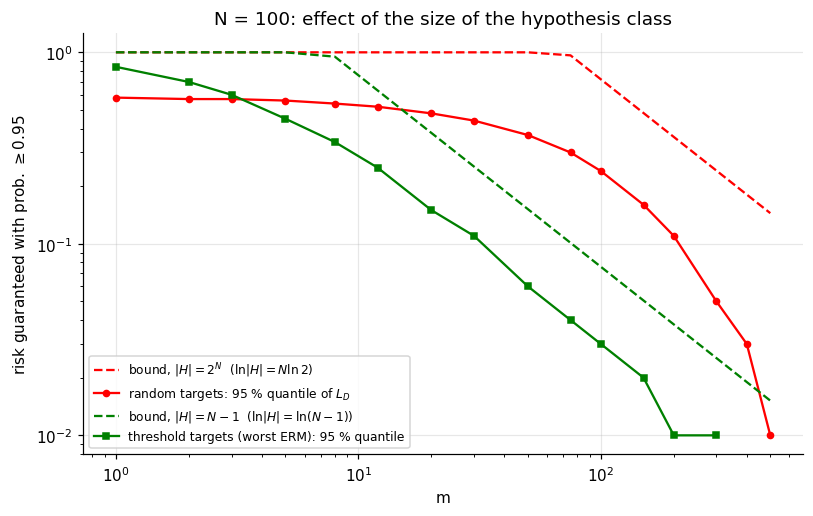

,m,bound |H|=2^N,"95% quantile, random targets",bound |H|=N-1,"95% quantile, thresholds (worst ERM)"
0,20,1.0000,0.48,0.3795,0.15
1,50,1.0000,0.37,0.1518,0.06
2,100,0.7231,0.24,0.0759,0.03
3,200,0.3616,0.11,0.0380,0.01
4,500,0.1446,0.01,0.0152,NaN


In [17]:
# Why is (b) so much faster?  The class "all labellings" has |H| = 2^N, the threshold class only |H| = N-1.
# Realizable finite-class bound: with probability >= 1-delta,  L_D(h_S) <= ln(|H|/delta) / m   for any ERM.
dl = 0.05
mm = np.array(m10)
q95_a = np.array([np.quantile(rnd[m]["risk_zero"], 1 - dl) for m in m10])        # memorisation = an ERM over all labellings
q95_b = np.array([np.quantile(thr10[m]["risk_worst"], 1 - dl) for m in m10])     # worst-case ERM over thresholds
bound_all = np.minimum(1, (N10 * np.log(2) + np.log(1 / dl)) / mm)
bound_thr = np.minimum(1, (np.log(N10 - 1) + np.log(1 / dl)) / mm)

plt.figure(figsize=(7.5, 4.8))
plt.loglog(mm, bound_all, "r--", label=r"bound, $|H|=2^N$  ($\ln|H|=N\ln 2$)")
q95_a, q95_b = np.where(q95_a > 0, q95_a, np.nan), np.where(q95_b > 0, q95_b, np.nan)   # zeros cannot be drawn on a log axis
plt.loglog(mm, q95_a, "ro-", ms=4, label="random targets: 95 % quantile of $L_D$")
plt.loglog(mm, bound_thr, "g--", label=r"bound, $|H|=N-1$  ($\ln|H|=\ln(N-1)$)")
plt.loglog(mm, q95_b, "gs-", ms=4, label="threshold targets (worst ERM): 95 % quantile")
plt.xlabel("m"); plt.ylabel(r"risk guaranteed with prob. $\geq 0.95$"); plt.title(f"N = {N10}: effect of the size of the hypothesis class")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

sel = [m10.index(m) for m in (20, 50, 100, 200, 500)]
display(pd.DataFrame({"m": mm[sel],
                      "bound |H|=2^N": bound_all[sel], "95% quantile, random targets": q95_a[sel],
                      "bound |H|=N-1": bound_thr[sel], "95% quantile, thresholds (worst ERM)": q95_b[sel]}).round(4))

In [18]:
# Samples needed to reach E[L_D] <= 0.05 as the domain grows
target = 0.05
m_small = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 40, 50, 60, 80, 100]
rows = []
for N in [50, 200, 1000]:
    mean_thr = [simulate_threshold(N, m, 1500)["risk_random"].mean() for m in m_small]
    m_thr = next((m for m, v in zip(m_small, mean_thr) if v <= target), np.nan)
    m_rnd = int(ceil(log(2 * target) / log(1 - 1 / N)))            # 0.5 (1-1/N)^m <= target
    rows.append({"N": N, "random targets (theory)": m_rnd, "threshold targets + ERM (simulation)": m_thr})
display(pd.DataFrame(rows))

,N,random targets (theory),threshold targets + ERM (simulation)
0,50,114,12
1,200,460,12
2,1000,2302,12


**Interpretation — why the learner generalizes in the structured setting.**
* **Curves.** At $m=20$ the expected risk is about 0.41 for random targets and 0.03 for thresholds; at $m=100=N$ it is 0.18 versus 0.005. The number of samples needed to reach 0.05 is about 12 for thresholds *whatever the domain size* (50, 200 or 1000), versus 114, 460 and 2302 for random targets. Back-of-the-envelope for thresholds: the consistent thresholds are confined to the gap between the nearest 0-labelled and 1-labelled sample points around $\theta$, of length about $2N/m$, which gives $\mathbb E[L_D]\approx\frac{2}{3m}$ for a random consistent threshold; the simulation gives $m\cdot\mathbb E[L_D]\approx0.6$ over a wide range of $m$.
* **What the threshold assumption does.** Under the threshold prior, labels are *not* independent across inputs: a point labelled 0 forces the label 0 on every smaller input and a point labelled 1 forces 1 on every larger one. A single example therefore carries information about a whole region of $\mathcal X$, including inputs never observed. For arbitrary targets the label of an unseen point is independent of everything the learner has seen, so there is nothing to extrapolate from.
* **Capacity view.** The thresholds have $\ln|\mathcal H|=\ln(N-1)$ (for $N=100$, about 4.6), the class of all labellings has $\ln|\mathcal H|=N\ln 2$ (about 69). The guarantee $\ln(|\mathcal H|/\delta)/m$ is therefore informative (below 1) from about 8 samples for thresholds, while for all labellings it is vacuous (≥ 1) until $m\approx N\ln2+\ln(1/\delta)\approx72$ — the same order as the $m\sim N$ needed in the memorisation experiment. In both cases the 95 % quantile of the simulated risk stays below the bound (the bound is valid but conservative, as in Part I). Restricting the hypotheses to a small class is what lets few examples determine the answer.
* **The assumption must be right.** The grey control curve shows what happens when the prior does not match the target: ERM over thresholds on random labellings stays around 0.43 even at $m=500$ — no amount of data fixes a wrong inductive bias, because the target is not in the class (the approximation error does not vanish). The bias helps exactly on the targets for which it is true, and nothing is gained for free: this is the No-Free-Lunch principle seen from the other side.

---
## Task 11 — Final analysis

**Concentration and uniform convergence.**
* *Why $L_S(h)$ concentrates around $L_D(h)$ as $m$ grows.* $L_S(h)$ is an average of $m$ i.i.d. bounded losses with mean $L_D(h)$: unbiased, with standard deviation $\sqrt{p(1-p)/m}$ (measured, then confirmed by the log–log plot with slope $-1/2$). Hoeffding's inequality turns this into a tail bound $2e^{-2m\epsilon^2}$ that decays exponentially in $m\epsilon^2$.
* *Why uniform convergence needs simultaneous control of all hypotheses.* ERM picks $h_S$ **using the sample**, so the hypothesis it returns is precisely the one whose empirical risk is likely to be too optimistic. A guarantee for each fixed $h$ is not enough; we need $\Delta_S\le\epsilon$, i.e. an $\epsilon$-representative sample, which then gives $L_D(h_S)\le\min_{h\in\mathcal H}L_D(h)+2\epsilon$. The simulation shows how much stronger this requirement is: with $|\mathcal H|=50$ and $m\approx500$ some hypothesis deviates by more than 0.05 in 46–71 % of the samples, while a fixed hypothesis would do so rarely.
* *How $|\mathcal H|$ affects it.* More hypotheses means more chances for one of them to deviate: the failure probability grows roughly linearly in $|\mathcal H|$ and saturates at 1. In sample-size terms the cost is only $\ln|\mathcal H|/(2\epsilon^2)$, with a measured slope within 2–15 % of the theoretical one — a 100-fold larger class needs only about 2.3 times more data at $\epsilon=0.05$.
* *Why the finite-class bounds are conservative.* They are valid for all distributions, all true risks and any dependence between hypotheses. Hoeffding ignores the variance (very loose for low-variance hypotheses and loses a polynomial prefactor even at $p=\tfrac12$); the union bound counts overlapping failure events separately; the sample size is rounded up. We observed $m_{th}/m_{exp}\in[1.2,1.9]$ and failure probabilities one to two orders of magnitude below $\delta$ at the theoretical $m$ — yet the bound is never violated and its logarithmic growth in $|\mathcal H|$ is essentially exact.

**No-Free-Lunch.**
* *Why random targets make unseen labels unpredictable.* When every label is an independent fair coin, the label of an unseen input is independent of all the observed examples. Whatever the learner predicts there is right with probability $\tfrac12$: the expected risk is $\tfrac12(1-1/N)^m$ for memorisation, matching the simulations (largest deviation 2.65 standard errors over 32 settings), and it is the same for the rules "always 0", "always 1" and "coin".
* *What the experiment shows.* The learner fits what it has seen and is at chance on the rest; it needs $m\sim N\ln\frac1{2\varepsilon}$ samples to leave only an $\varepsilon$ fraction of the domain unseen. No rule is uniformly better — each wins on targets biased in its favour and loses on the opposite ones — and the lower bound $\mathbb E[L_D]\ge\tfrac12(1-1/N)^m$ holds for every learner. A learner cannot infer arbitrary unseen labels from the training sample alone.

**Inductive bias.**
* *Prior knowledge.* Restricting both the targets and the hypotheses to thresholds says that labels are monotone in $x$. This is a strong assumption — a class of $N-1$ functions instead of $2^N$ — and it correlates the labels of seen and unseen points.
* *Why it enables generalization.* Each example now constrains a whole region of the domain: the uncertainty is confined to a gap of length $\approx 2N/m$, the risk decays like $1/m$ independently of $N$ (about 12 samples to reach 0.05 for $N=50,200,1000$, against 114, 460, 2302 for random targets), and the guarantee $\ln(|\mathcal H|/\delta)/m$ depends on $\ln|\mathcal H|=\ln(N-1)$ instead of $N\ln 2$.
* *But it is a bet, not a free lunch.* With the same learner and random targets the risk remains near 0.43 at $m=500$: the bias pays off only because the target really belongs to the class. Uniform convergence tells us how much data a class of a given size needs; the choice of the class — the inductive bias — decides whether low true risk is attainable at all.

**Limits of the simulations.** In Part I the errors of the hypotheses are independent Binomials with fixed $p_j$ (real hypotheses have correlated errors and the $p_j$ depend on the distribution); Parts II and III use a uniform distribution on a finite domain. These choices make exact comparisons with theory possible, and the qualitative conclusions above do not depend on them.